# T09 — Small multi-particle, multi-forcing-member Stage III run, manual check

Scope (per `tasks.md` T09 and the 2026-09-22 task instructions): run the *existing,
unmodified* T05/T06 backward-adjoint pipeline for a small set of upstream particles
(T07's `adapt_upstream_particles`) across a small set of forcing members (T08's
`ForcingEnsemble`), and record `(particle, forcing_member, checkpoint)` rows with
`timestamp`, `lat`, `lon`, `log_weight`, `observation_pixel_id`, `forcing_member_id`,
`valid`. No particle generation, no T10 diagnostics module, no KDE/likelihood/SMC/MCMC/
AIS, no production-scale run.

**Every forcing-member perturbation used here is still the T08 PROTOTYPE — NOT
VALIDATED — model.**

In [1]:
import os
import sys
import time

REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), os.pardir))
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

import numpy as np
import matplotlib.pyplot as plt

from iste.environment import load_field_dataset
from iste.observation import adapt_upstream_particles
from iste.forcing_ensemble import ForcingEnsemble, ForcingEnsembleConfig
from iste.ensemble_run import run_ensemble, compute_diagnostics, compute_diagnostics_by_member

OCEAN_PATH = os.path.join(REPO_ROOT, "data", "ocean.nc")
ocean = load_field_dataset(OCEAN_PATH, ["uo", "vo"], time_dim="time", lat_dim="latitude", lon_dim="longitude")

c:\Users\venka\AppData\Local\Programs\Python\Python313\Lib\site-packages\argopy\utils\lists.py:38: UserWarning: An error occurred while loading the ERDDAP data fetcher, it will not be available !
<class 'ImportError'>
cannot import name '_quote_string_constraints' from 'erddapy.erddapy' (c:\Users\venka\AppData\Local\Programs\Python\Python313\Lib\site-packages\erddapy\erddapy.py)
  warnings.warn(
c:\Users\venka\AppData\Local\Programs\Python\Python313\Lib\site-packages\argopy\utils\lists.py:50: UserWarning: An error occurred while loading the ArgoVis data fetcher, it will not be available !
<class 'ImportError'>
cannot import name '_quote_string_constraints' from 'erddapy.erddapy' (c:\Users\venka\AppData\Local\Programs\Python\Python313\Lib\site-packages\erddapy\erddapy.py)
  warnings.warn(
c:\Users\venka\AppData\Local\Programs\Python\Python313\Lib\site-packages\argopy\utils\lists.py:66: UserWarning: An error occurred while loading the GDAC data fetcher, it will not be available !
<class 

## 1. Small smoke-test configuration

Documented, deliberately small development values -- **not** `E=50` at production
particle counts.

In [2]:
t0 = ocean.time[50]  # an arbitrary real observation instant

# a mock stand-in for T07's upstream particle payload -- 4 particles from 2 observation
# pixels, one already marked invalid by the (hypothetical) upstream teammate module.
mock_upstream_payload = [
    {"particle_id": "p0", "latitude": 33.0, "longitude": 30.0, "observation_pixel_id": "px-0", "timestamp": t0},
    {"particle_id": "p1", "latitude": 33.15, "longitude": 30.15, "observation_pixel_id": "px-0", "timestamp": t0},
    {"particle_id": "p2", "latitude": 34.0, "longitude": 31.0, "observation_pixel_id": "px-1", "timestamp": t0},
    {"particle_id": "p3", "latitude": 34.1, "longitude": 31.1, "observation_pixel_id": "px-1", "timestamp": t0, "valid": False},
]
particles = adapt_upstream_particles(mock_upstream_payload)

N_MEMBERS_TOTAL = 5      # small ensemble (not E=50)
FORCING_MEMBER_IDS = [0, 1, 2]   # use only 3 of the 5 configured members for this run
N_STEPS = 8               # small window
DT_SECONDS = 900.0        # 15-minute checkpoints (within the README-required 15-30 min range)

ensemble = ForcingEnsemble(ocean, ForcingEnsembleConfig(n_members=N_MEMBERS_TOTAL, master_seed=7))
k_field = np.zeros((len(ocean.lat), len(ocean.lon)))  # K still undefined -- synthetic zero field

print(f"{particles.n_particles} particles x {len(FORCING_MEMBER_IDS)} forcing members x "
      f"{N_STEPS + 1} checkpoints ({N_STEPS} steps of {DT_SECONDS/60:.0f} min)")
print(f"backward window: {N_STEPS * DT_SECONDS / 3600:.2f} hours")

4 particles x 3 forcing members x 9 checkpoints (8 steps of 15 min)
backward window: 2.00 hours


## 2. Run it, and measure runtime / memory

In [3]:
t_start = time.time()
records = run_ensemble(
    particles, FORCING_MEMBER_IDS, N_STEPS, DT_SECONDS, ocean, ensemble,
    ocean.lat, ocean.lon, k_field, master_seed=42,
)
elapsed = time.time() - t_start

records_bytes = (
    records.timestamp.nbytes + records.lat.nbytes + records.lon.nbytes
    + records.log_weight.nbytes + records.valid.nbytes
    + sum(len(str(x)) for x in records.particle_id) + sum(len(str(x)) for x in records.observation_pixel_id)
)
cached_env_bytes = sum(ensemble.member_state_nbytes(m) for m in FORCING_MEMBER_IDS)

print(f"runtime: {elapsed:.3f} s for {records.n_records} records")
print(f"records memory (approx): {records_bytes/1024:.1f} KB")
print(f"forcing-ensemble cached state ({len(FORCING_MEMBER_IDS)} members): {cached_env_bytes/1024/1024:.2f} MB")
print("(base uo/vo arrays are referenced, not duplicated; no full perturbed grid is stored for any member.)")

runtime: 0.536 s for 84 records
records memory (approx): 3.2 KB
forcing-ensemble cached state (3 members): 18.92 MB
(base uo/vo arrays are referenced, not duplicated; no full perturbed grid is stored for any member.)


## 3. Trajectory examples: forcing-member IDs and observation-pixel IDs

In [4]:
print(f"{'particle_id':>11} {'member':>6} {'pixel_id':>8} {'checkpoints':>11}")
for pid in np.unique(records.particle_id):
    for member_id in FORCING_MEMBER_IDS:
        mask = (records.particle_id == pid) & (records.forcing_member_id == member_id)
        n = int(np.sum(mask))
        pixel = records.observation_pixel_id[mask][0]
        print(f"{pid:>11} {member_id:>6} {str(pixel):>8} {n:>11}")

particle_id member pixel_id checkpoints
         p0      0     px-0           9
         p0      1     px-0           9
         p0      2     px-0           9
         p1      0     px-0           9
         p1      1     px-0           9
         p1      2     px-0           9
         p2      0     px-1           9
         p2      1     px-1           9
         p2      2     px-1           9
         p3      0     px-1           1
         p3      1     px-1           1
         p3      2     px-1           1


### One particle's trajectory across its forcing members (plot)

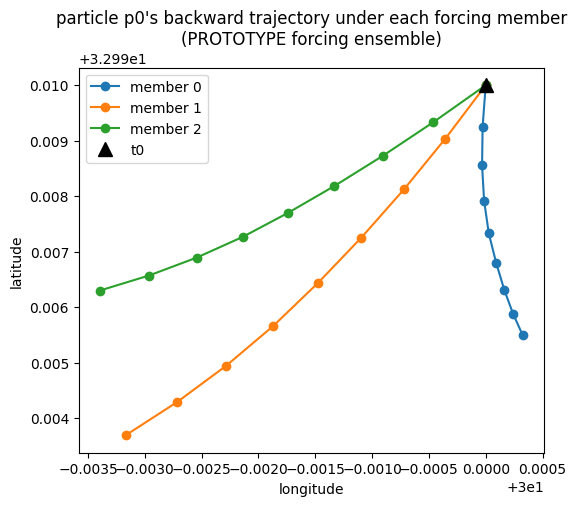

In [5]:
fig, ax = plt.subplots(figsize=(6, 5))
colors = {0: "tab:blue", 1: "tab:orange", 2: "tab:green"}
for member_id in FORCING_MEMBER_IDS:
    mask = (records.particle_id == "p0") & (records.forcing_member_id == member_id)
    ax.plot(records.lon[mask], records.lat[mask], "o-", color=colors[member_id], label=f"member {member_id}")
ax.plot(records.lon[(records.particle_id == "p0") & (records.forcing_member_id == FORCING_MEMBER_IDS[0])][0],
        records.lat[(records.particle_id == "p0") & (records.forcing_member_id == FORCING_MEMBER_IDS[0])][0],
        "k^", markersize=10, label="t0")
ax.set_xlabel("longitude"); ax.set_ylabel("latitude")
ax.set_title("particle p0's backward trajectory under each forcing member\n(PROTOTYPE forcing ensemble)")
ax.legend()
plt.show()

### Forcing-member coherence: nearby particles under the SAME member track together

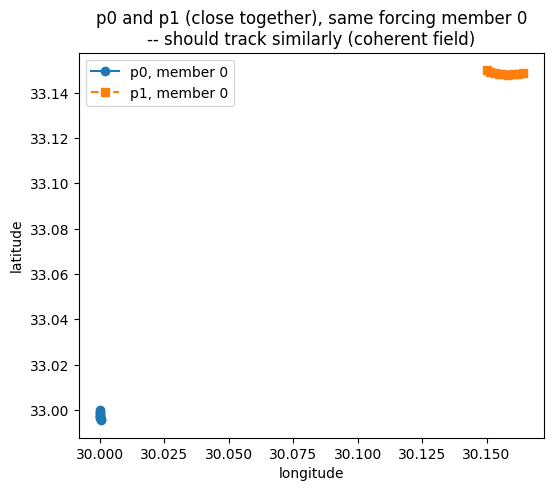

In [6]:
fig, ax = plt.subplots(figsize=(6, 5))
for pid, style in [("p0", "o-"), ("p1", "s--")]:
    mask = (records.particle_id == pid) & (records.forcing_member_id == 0)
    ax.plot(records.lon[mask], records.lat[mask], style, label=f"{pid}, member 0")
ax.set_xlabel("longitude"); ax.set_ylabel("latitude")
ax.set_title("p0 and p1 (close together), same forcing member 0\n-- should track similarly (coherent field)")
ax.legend()
plt.show()

## 4. Diagnostic summary

In [7]:
overall = compute_diagnostics(records)
print("overall (all particles x forcing members, at final checkpoint):")
print(f"  total_particles={overall.total_particles}, valid={overall.valid_particles}, "
      f"invalid={overall.invalid_particles}")
print(f"  total_weight={overall.total_weight:.4f}, effective_sample_size={overall.effective_sample_size:.4f}, "
      f"valid_particle_fraction={overall.valid_particle_fraction:.3f}")

print("\nby forcing member:")
for member_id, diag in sorted(compute_diagnostics_by_member(records).items()):
    print(f"  member {member_id}: total={diag.total_particles}, valid={diag.valid_particles}, "
          f"invalid={diag.invalid_particles}, total_weight={diag.total_weight:.4f}, "
          f"ESS={diag.effective_sample_size:.4f}, valid_fraction={diag.valid_particle_fraction:.3f}")

overall (all particles x forcing members, at final checkpoint):
  total_particles=12, valid=9, invalid=3
  total_weight=9.2481, effective_sample_size=8.9993, valid_particle_fraction=0.750

by forcing member:
  member 0: total=4, valid=3, invalid=1, total_weight=3.0854, ESS=2.9995, valid_fraction=0.750
  member 1: total=4, valid=3, invalid=1, total_weight=3.0813, ESS=2.9999, valid_fraction=0.750
  member 2: total=4, valid=3, invalid=1, total_weight=3.0815, ESS=3.0000, valid_fraction=0.750


### Confirming the already-invalid upstream particle (`p3`) is retained, not dropped

In [8]:
mask_p3 = records.particle_id == "p3"
print(f"p3 rows: {int(np.sum(mask_p3))} (expected: 1 per forcing member = {len(FORCING_MEMBER_IDS)})")
print(f"p3 valid: {records.valid[mask_p3]}")
print(f"p3 pixel_id: {set(records.observation_pixel_id[mask_p3].tolist())}")
assert int(np.sum(mask_p3)) == len(FORCING_MEMBER_IDS)
assert not np.any(records.valid[mask_p3])

p3 rows: 3 (expected: 1 per forcing member = 3)
p3 valid: [False False False]
p3 pixel_id: {'px-1'}


## Summary / known limitations

- This run reused T05/T06 completely unmodified -- every displacement/weight update came
  from `backward_euler_maruyama_step`; T09 only orchestrates it per (particle, forcing
  member) pair and injects T08's perturbation via a lazy, on-demand `GriddedFieldSource`
  view (`make_perturbed_source`) -- never duplicating the base `uo`/`vo` arrays or
  precomputing a full perturbed grid for any member.
- Every particle under the same forcing member sees the identical coherent perturbation
  realization at the same query time (visible above: `p0`/`p1` under member 0 track
  together; different members diverge).
- `observation_pixel_id`, `particle_id`, and `forcing_member_id` are preserved exactly
  through every checkpoint.
- Invalid particles -- both already-invalid upstream (`p3`) and any that would hit land
  during propagation -- are always retained as explicit rows, never dropped.
- `total_particles`/`valid_particles`/`invalid_particles`/`total_weight`/
  `effective_sample_size`/`valid_particle_fraction` are computed at each
  (particle, forcing-member) trajectory's final checkpoint, both overall and per member --
  this is the minimum diagnostic needed to sanity-check this small run, not T10's
  dedicated diagnostics module.
- Runtime and memory are small at this scale (see §2) — this is a smoke test, not a
  production-scale (`E≈50`, full particle-cloud) run, and no such run was attempted.
- Every forcing-member perturbation used is still the T08 **PROTOTYPE — NOT VALIDATED**
  model (20 km / 1 day / 0.05 m/s). `K` remains an undefined, synthetic zero field.
- No T10 diagnostics module, KDE, likelihood, SMC, MCMC, or AIS exists in this
  repository.